# Function 8: pooled cohort observation review

**Side quest — 20 October 2026.** A copy of the [Week 4 notebook](../../../../../notebooks/Function_8/Week_04/observation_review.ipynb),
using **49 observations**: 40 shared initial points,
3 confirmed own returns and **6 additional peer records**.
The methods, target treatments and search settings are retained. Peer data are
published reports, not independently verified portal returns. See the
[dataset audit](../../../dataset-audit.json) for exact sources and exclusions.

Week 4 has already been submitted. Any original coverage plan is a historical
reference; any newly calculated suggestion here is hypothetical. This pooled
snapshot includes records collected later, so its validation is not a forecast
made before the original Week 3 return. Query-budget numbers refer to the
original start of Week 4 and confer no additional evaluation allowance.


## Function description and cohort clues

**Course description, paraphrased.** Optimise eight influential inputs. The lesson favours practical strong local maxima when global search is difficult in the high-dimensional domain.

Source: [Mini-lesson 12.8: function descriptions](https://classroom.emeritus.org/courses/18642/modules/items/3237303), reviewed
20 October 2026. The notes below interpret the fixed cohort snapshot collected
on that date. Peer outputs are published reports, not independently verified
portal returns. Every official objective remains maximisation of signed y.

### What the cohort observations suggest

The five strongest of **49 records** keep x1–x4 low, especially x1 and x4.
The other four settings vary considerably. This suggests a promising region;
compensating effects could explain similarly good outputs from different
combinations, so those inputs cannot be declared irrelevant.

| Evidence | Output |
| --- | ---: |
| Best shared initial observation | 9.598482 |
| Best peer-reported observation | 9.890878 |
| Best own returned query | 9.518300 |
| Latest own query | 8.798303 |

Pooling improves the known incumbent; own returns have not beaten the supplied
best. A controlled comparison between own rounds 1 and 2 changed only x8 from
**0 to 0.999999**, increasing output by approximately **0.020**. That is a small
effect for this particular combination, not proof of global irrelevance. Raising
x4 and x6 together from the round 1 settings reduced output by about **0.700**;
their separate contributions remain unresolved.

### Exploration implication

Refine the low-x1–x4 neighbourhood around the peer's 9.891 result while keeping
the remaining inputs available. The brief says all eight affect output, without
implying equal influence. Its named hyperparameters and 0–1 accuracy are examples,
not verified input types or the actual score scale. Actual outputs are roughly
5.6–9.9, and neither 1 nor 10 is imposed as a ceiling. Strong local maxima are a
practical aim; 49 selected observations do not map the full eight-dimensional box.

These patterns describe selected observations, not controlled causal effects or a known true surface. Exploration suggestions are hypotheses for the side quest, not submissions.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_8/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish the pooled evidence

The common supplied observations form one initial batch. Later rows retain
the round reported in each peer history; an ordered history without explicit
round numbers uses its recorded query order. Coverage across repositories is
incomplete. Several returned queries can belong to the same round.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 8.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 40, 1: 5, 2: 3, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Published completed rounds: {returned.source_round.nunique()}; pooled returned queries: {len(returned)}")

,Evidence,Count
0,Input dimensions,8
1,Initial observations,40
2,Returned queries,9
3,Total observations,49
4,"Queries available, including Week 4",10


Published completed rounds: 3; pooled returned queries: 9


## 2. Place the latest recorded round among the pooled outputs

The own round 3 return is **8.7983**, ranked **15/49 (1 = highest)**
in the pooled data. The best published output is **9.89088** from
`peer-kosina-round-01`. These rankings describe the available records, with
the precision and reporting limitations documented in the audit.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 48 earlier observations (49 outputs in total).
Earlier output range: [5.592193, 9.89087768385].

round-03: y = 8.7983029 (positive); rank 15/49 (1 = highest output).
Inputs: x1 = 0, x2 = 0, x3 = 0, x4 = 0.999999, x5 = 0.999999, x6 = 0.999999, x7 = 0, x8 = 0
Within the earlier output range.


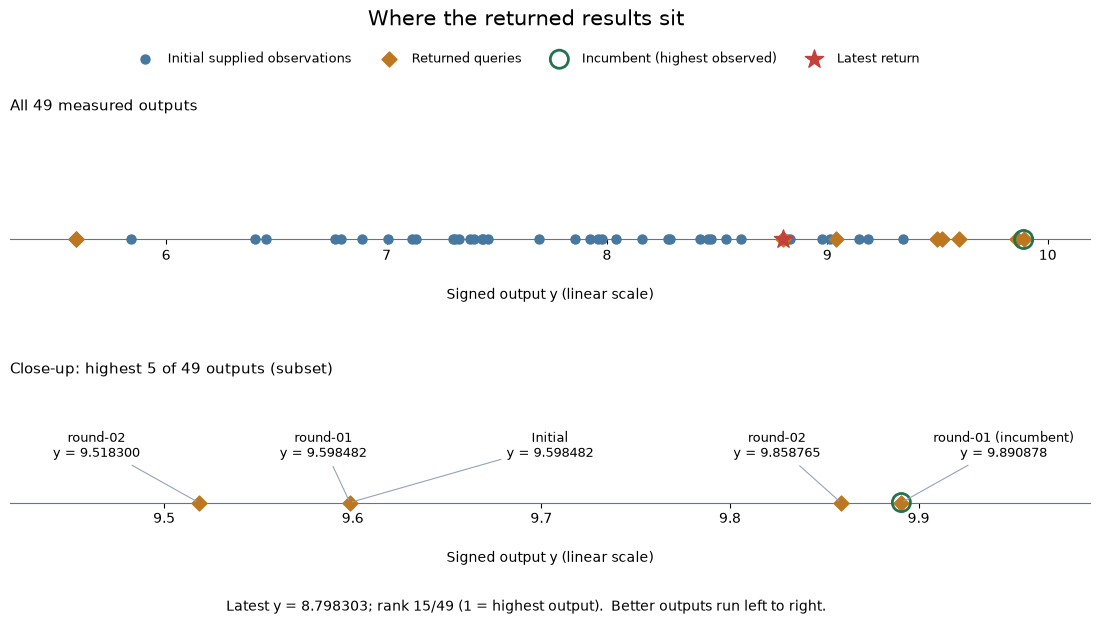

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

The full number line retains all 49 measured/reported outputs. The
close-up labels the highest five, retaining their actual spacing. Moving right
means a higher output. This selected sample does not estimate the distribution
of outputs across the domain. A missing peer return is not a zero.

## 3. Track the best published output across rounds

For each reported round, show its highest returned output and the best seen
through that round. Several peers can contribute; this is a pooled record,
not a measure of one person's strategy. Repository coverage is incomplete.

In [5]:
running_best = float(initial['y'].max())
progress_rows = [{'source_round': 0, 'stage': 'Initial batch', 'returned_y': np.nan,
                  'best_y': running_best, 'change_vs_prior_best': np.nan}]
for round_number, group in returned.groupby('source_round', sort=True):
    value = float(group['y'].max())
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({'source_round': int(round_number), 'stage': f'Round {round_number}',
                          'returned_y': value, 'best_y': running_best,
                          'change_vs_prior_best': change})
progress = pd.DataFrame(progress_rows)
display(progress.set_index('stage').style.format(precision=6, na_rep='—'))


,source_round,returned_y,best_y,change_vs_prior_best
stage,,,,
Initial batch,0,—,9.598482,—
Round 1,1,9.890878,9.890878,0.292396
Round 2,2,9.858765,9.890878,-0.032112
Round 3,3,8.798303,9.890878,-1.092575


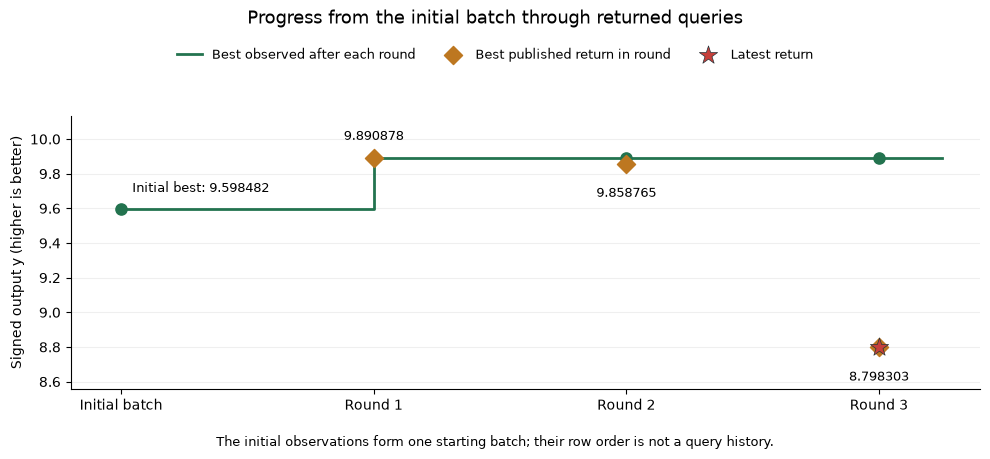

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

The pooled incumbent changes from **9.59848** in the
shared initial data to **9.89088**. The own-data incumbent
is **9.59848**. Access to other people's experiments changes
the evidence budget, so this comparison cannot demonstrate that our strategy
outperformed theirs, or vice versa.

## 4. Examine the strongest input combinations

Keep all eight coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y
observation_id,,,,,,,,,,,
peer-kosina-round-01,1,1,0.052325,0.141964,0.124313,0.014745,0.921651,0.374929,0.039243,0.262463,9.890878
peer-kosina-round-02,2,2,0.052325,0.000000,0.124313,0.014745,0.999999,0.641250,0.299616,0.000000,9.858765
initial-015,3,0,0.056447,0.065956,0.022929,0.038786,0.403935,0.801055,0.488307,0.893085,9.598482
peer-tomxandrews-round-01,4,1,0.045000,0.055000,0.020000,0.035000,0.415000,0.810000,0.495000,0.905000,9.598482
round-02,5,2,0.000000,0.000000,0.000000,0.000000,0.999999,0.000000,0.000000,0.999999,9.518300


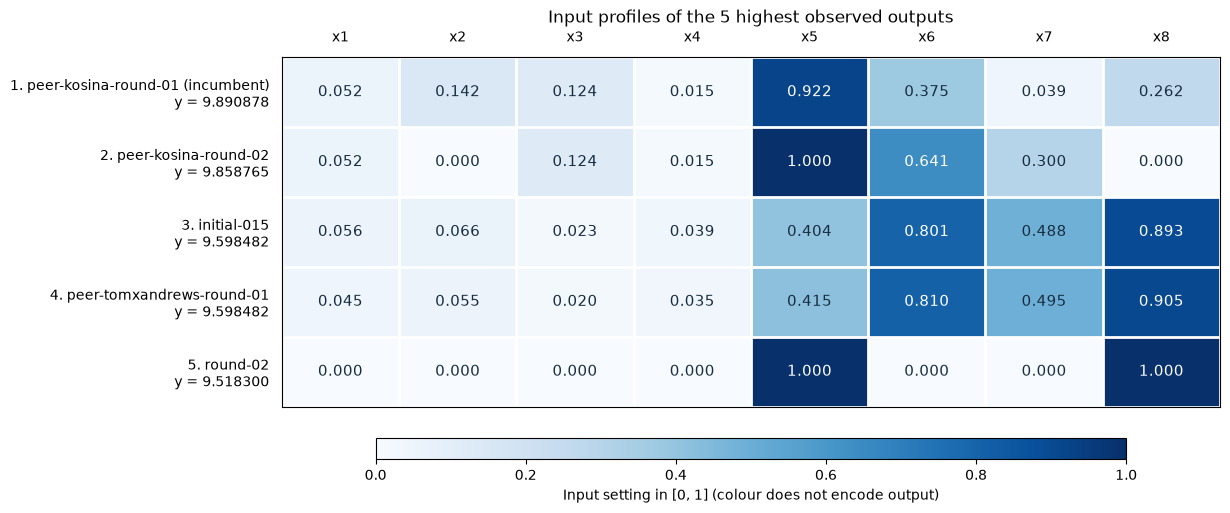

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

Read each row as one complete measured/reported combination. The input
colours describe settings, while the row label reports its output. Rows can
have very different performance even when neighbouring in rank. Compare all
coordinates before suggesting a pattern; these are not controlled tests of
one input at a time.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full eight-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.052325,0.000000,-0.052325
x2,0.141964,0.000000,-0.141964
x3,0.124313,0.000000,-0.124313
x4,0.014745,0.999999,0.985254
x5,0.921651,0.999999,0.078348
x6,0.374929,0.999999,0.625070
x7,0.039243,0.000000,-0.039243
x8,0.262463,0.000000,-0.262463


Previous best: peer-kosina-round-01; y = 9.890878
Full eight-input distance to previous best: 1.215051
Latest output minus previous best: -1.092575
Nearest earlier observation: initial-027 (distance 1.092101)
Repeated full input combinations: 0


The full-input distance and output difference above compare the own round 3
query with the best published record from earlier reported rounds. Distances
do not identify causal effects or account for differing input relevance.
Published precision and potential reporting mistakes remain limitations.

## 5. Continue with the pooled model study

Open [model predictions](model_predictions.ipynb) to compare the same methods
on this larger dataset, inspect held-out errors and uncertainty, and calculate
a hypothetical query. The official submission is unchanged.

**Provenance:** the audit retains commit-pinned GitHub URLs, source locations,
duplicate matches and excluded records. Initial arrays from three peer
repositories matched the authorised starting data exactly and were included once.